# Детекция объектов: от изображения к рамкам

В уроке сегментации мы определяли класс каждого пикселя. Теперь найдём отдельные
объекты и каждый обозначим своей рамкой. Что должна предсказать
сеть и как понять, что она нашла объекты правильно?

**Что будем делать:**

1. Получим рамки из разметки и посмотрим, как ошибка в resize может сломать таргет.
2. Разберём путь от R-CNN до Faster R-CNN.
3. На небольших примерах поймём, как работает NMS и оценка AP.
4. Обучим один и тот же детектор с нуля и с предобученных COCO-весов, сравним метрики и ошибки.
5. Проверим пороги предсказаний и размер входа, сохраним модель и ответы.

В дополнительном разделе познакомимся с идеями YOLO и DETR.

**Запуск:** загрузите только этот ноутбук в Colab/Kaggle и нажмите **Run all**.
Нужен интернет для данных, исходных весов (вместе около **125 МБ**) и недостающих
библиотек. В Kaggle включите Internet. Обучим две модели по **30 эпох**; для этого опыта
выберите GPU: например, в Colab **Среда выполнения -> Сменить среду выполнения -> T4 GPU**.
Первая ячейка напечатает название видеокарты. На CPU обучение возможно, но займёт гораздо больше времени.

Подробнее о формате входа и выхода детектора можно почитать в
[официальном примере из документации PyTorch](https://docs.pytorch.org/tutorials/intermediate/torchvision_tutorial.html).


In [1]:
import importlib.util
import subprocess
import sys

packages = {"torch": "torch>=2.5", "torchvision": "torchvision>=0.20",
            "numpy": "numpy", "PIL": "Pillow", "matplotlib": "matplotlib",
            "torchmetrics": "torchmetrics>=1.6,<2", "pycocotools": "pycocotools>=2.0.8,<3"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])

import json
import random
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn, FasterRCNN_MobileNet_V3_Large_320_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou, nms, FrozenBatchNorm2d
from torchmetrics.detection import MeanAveragePrecision

SEED = 42
BATCH_SIZE = 2
EPOCHS = 30  # для каждой из двух моделей
LR_MILESTONES = [15, 25]
LEARNING_RATE = 0.005
MIN_SIZE = 320
SHOW_SCORE = 0.5  # порог только для картинок; при подсчёте mAP его не применяем
WORK = (Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()) / "detection_lab"
WORK.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(2)
torch.hub.set_dir(str(WORK / "weights"))

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(SEED)
print("PyTorch:", torch.__version__, "| устройство:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Для полного опыта на 30 эпох рекомендуем включить GPU.")


PyTorch: 2.11.0+cu130 | устройство: cuda
GPU: Tesla T4


## 1. Сначала посмотрим на объекты и рамки

Возьмём [Penn-Fudan](https://www.cis.upenn.edu/~jshi/ped_html/): 170 фотографий
пешеходов. В исходном датасете есть маски отдельных экземпляров: каждый человек имеет свой номер. Чтобы получить
рамку, найдём крайние пиксели каждого объекта и обведём их прямоугольником.
Маска здесь служит источником разметки боксов (прямоугольных рамок) для обучения.
Правильную разметку дальше будем называть **GT (ground truth)**.

Номер экземпляра и класс - разные вещи. У всех людей будет класс `1`,
а `0` зарезервирован для фона. Слева покажем общую маску людей, справа -
отдельные рамки.

В обучающую выборку попадут 96 Penn-фотографий, в валидационную и тестовую -
две группы Fudan: 49 и 25 фотографий. Так похожие сцены не перемешиваются случайно.
Тестовую выборку оценим один раз после выбора финальной модели.


In [2]:
import urllib.request
from zipfile import ZipFile

DATA = WORK / "PennFudanPed"
if not (DATA / "PNGImages").is_dir() or not (DATA / "PedMasks").is_dir():
    archive = WORK / "PennFudanPed.zip"
    print("Скачиваем Penn-Fudan, около 51 МБ…")
    with urllib.request.urlopen("https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip", timeout=60) as response:
        archive.write_bytes(response.read())
    with ZipFile(archive) as zipped:
        zipped.extractall(WORK)

names = sorted(path.stem for path in (DATA / "PNGImages").glob("*.png"))
assert len(names) == 170, "Ожидаются 170 изображений: проверьте загрузку"
train_names = [name for name in names if name.startswith("Penn")]
val_names = [name for name in names if name.startswith("Fudan") and not 41 <= int(name[-5:]) <= 65]
test_names = [name for name in names if name.startswith("Fudan") and 41 <= int(name[-5:]) <= 65]
print(f"train: {len(train_names)}, validation: {len(val_names)}, test: {len(test_names)}")


Скачиваем Penn-Fudan, около 51 МБ…
train: 96, validation: 49, test: 25


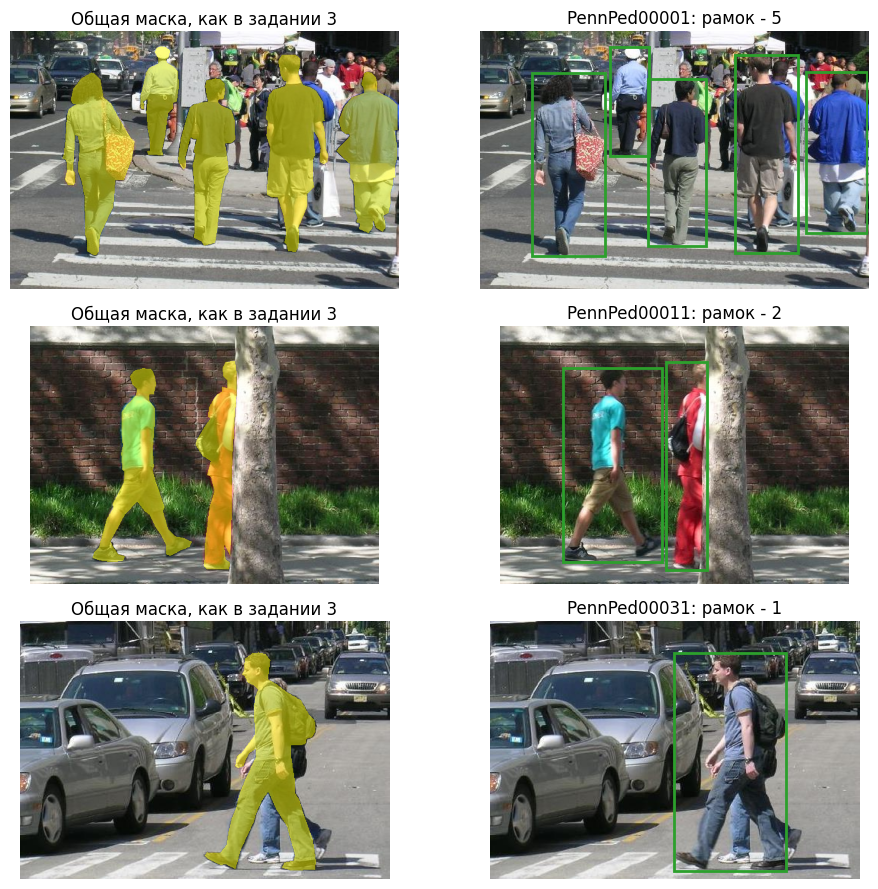

In [3]:
def read_example(name):
    with Image.open(DATA / "PNGImages" / f"{name}.png") as source:
        image = source.convert("RGB")
    with Image.open(DATA / "PedMasks" / f"{name}_mask.png") as source:
        mask = np.array(source)
    boxes = []
    for instance in np.unique(mask):
        if instance == 0:
            continue
        y, x = np.where(mask == instance)
        boxes.append([x.min(), y.min(), x.max() + 1, y.max() + 1])
    target = {"boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
              "labels": torch.ones(len(boxes), dtype=torch.int64)}
    return image, target

def draw_boxes(ax, boxes, scores=None, color="tab:green"):
    for i, (x1, y1, x2, y2) in enumerate(torch.as_tensor(boxes).cpu().tolist()):
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor=color, linewidth=2))
        if scores is not None:
            # Разносим подписи по высоте, чтобы соседние рамки читались.
            ax.annotate(f"{float(scores[i]):.2f}", (x1, y1), xytext=(2, -3 - 12 * (i % 3)),
                        textcoords="offset points", va="top", color="white", fontsize=9,
                        bbox=dict(facecolor=color, alpha=0.8, edgecolor="none"))

fig, axes = plt.subplots(3, 2, figsize=(10, 9))
for row, name in zip(axes, [train_names[i] for i in [0, 10, 30]]):
    image, target = read_example(name)
    with Image.open(DATA / "PedMasks" / f"{name}_mask.png") as source:
        mask = np.array(source) > 0
    row[0].imshow(image)
    row[0].imshow(np.ma.masked_where(~mask, mask), cmap="autumn", alpha=0.5, vmin=0, vmax=1)
    row[1].imshow(image); draw_boxes(row[1], target["boxes"])
    for ax, title in zip(row, ["Общая маска, как в задании 3", f"{name}: рамок - {len(target['boxes'])}"]):
        ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()


Общая маска отмечает класс «человек», но не хранит отдельные экземпляры.
Справа каждому экземпляру соответствует своя рамка, хотя класс у всех один.
В батче число объектов на разных изображениях будет разным - посмотрим, как это обрабатывать.


## 2. Изображения и рамки в батче

У одного фото две рамки, у другого пять. Поэтому таргет (разметка для обучения) хранит **список объектов**,
а не маску фиксированного размера. Для каждого объекта нужны координаты и класс.

Рамка задаётся краями `(xmin, ymin, xmax, ymax)` в пикселях исходного изображения.
Например, `[10, 20, 50, 80]` - прямоугольник шириной 40 и высотой 60.
В `read_example` прибавляем 1 к последнему занятому пикселю, чтобы включить объект целиком.

Батч состоит из **списка изображений и списка словарей** с `boxes` и `labels`.
`collate_fn` собирает эти списки в батч, сохраняя разное число объектов и размеры фото.
RGB переводим в `[0,1]`; изменение размера и нормализацию выполнит сам детектор.


In [4]:
def image_tensor(image):
    return torch.from_numpy(np.array(image.convert("RGB"))).permute(2, 0, 1).float() / 255

class PersonDataset(Dataset):
    def __init__(self, names):
        self.names = list(names)
    def __len__(self):
        return len(self.names)
    def __getitem__(self, index):
        image, target = read_example(self.names[index])
        return image_tensor(image), target

def collate_fn(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)

train_dataset = PersonDataset(train_names)
val_loader = DataLoader(PersonDataset(val_names), batch_size=BATCH_SIZE, collate_fn=collate_fn, num_workers=0)
images, targets = collate_fn([train_dataset[0], train_dataset[10]])
for image, target in zip(images, targets):
    print("RGB:", tuple(image.shape), "| boxes:", tuple(target["boxes"].shape),
          "| labels:", target["labels"].tolist())


RGB: (3, 406, 612) | boxes: (5, 4) | labels: [1, 1, 1, 1, 1]
RGB: (3, 376, 508) | boxes: (2, 4) | labels: [1, 1]


### Частая ошибка resize: изображение и рамки в разных масштабах

Если преобразовать только размер изображения, координаты рамок останутся в старом масштабе: они съедут, хотя код продолжит работать.
Ниже намеренно испортим пример, а справа исправим его.

При resize координаты x умножаем на `new_width / old_width`,
координаты y - на `new_height / old_height`. В нашем `Dataset` внешнего resize нет:
детектор сам согласует изменение фото и рамок.


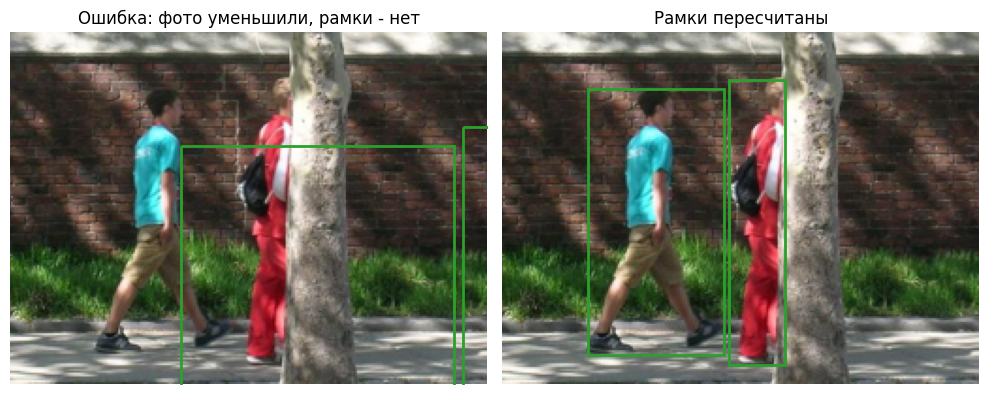

In [5]:
image, target = read_example(train_names[10])
small = image.resize((image.width // 2, image.height // 2))
scale = torch.tensor([small.width / image.width, small.height / image.height] * 2)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, boxes, title in zip(axes, [target["boxes"], target["boxes"] * scale],
                           ["Ошибка: фото уменьшили, рамки - нет", "Рамки пересчитаны"]):
    ax.imshow(small); draw_boxes(ax, boxes)
    ax.set(xlim=(0, small.width), ylim=(small.height, 0), title=title); ax.axis("off")
plt.tight_layout(); plt.show()


Слева рамки остались в координатах большого фото и съехали с людей.
Справа обе координаты x и обе координаты y пересчитаны в новый масштаб.
Так же нужно согласовывать изображение и рамки при геометрических аугментациях.


## 3. От R-CNN к Faster R-CNN

Как найти объекты, если их положение заранее неизвестно? Сначала можно предложить
области-кандидаты, а затем проверить каждую: есть ли там объект, какой это класс
и куда точнее поставить рамку? На этой идее построено семейство **R-CNN (Region-based Convolutional Neural Network)**.
На схеме проследите, где вычисляются признаки и откуда приходят области-кандидаты.


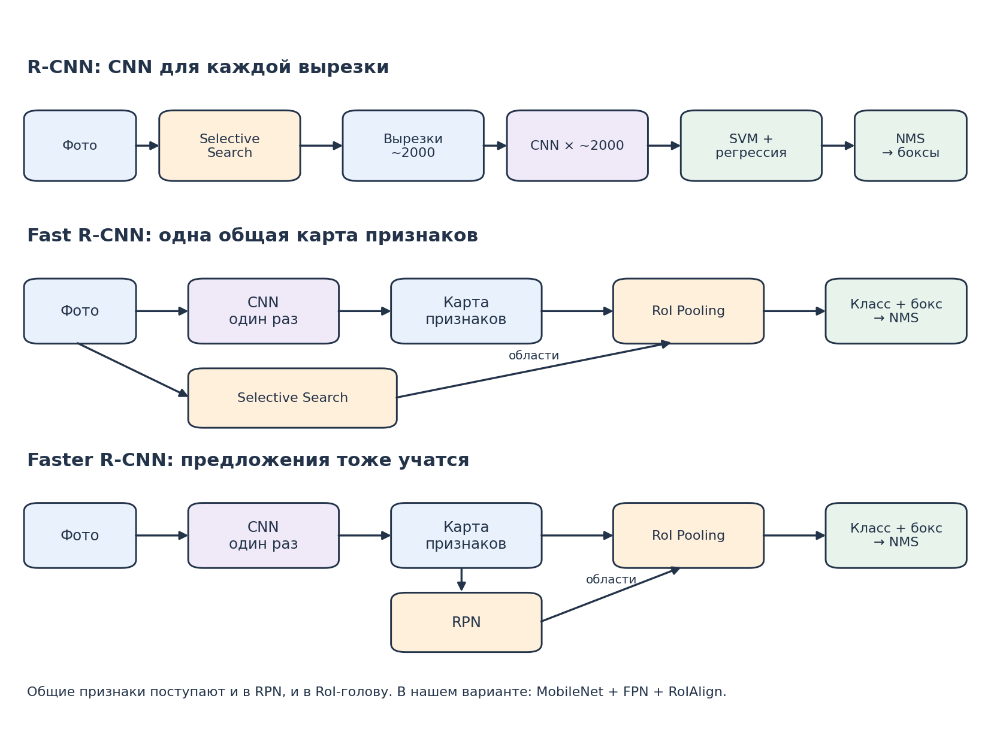


**R-CNN (2014): проверяем каждую область отдельно.** Selective Search предлагает
около 2000 областей по структуре изображения. Каждую область приводят к нужному
размеру и пропускают через CNN, чтобы получить вектор признаков. SVM определяет класс, регрессор поправляет рамку.
Области часто перекрываются, поэтому CNN много раз вычисляет признаки для одних
и тех же пикселей, а это в свою очередь замедляет работу модели. Кроме того, один объект может получить
несколько рамок. Убирать такие дубли будем с помощью **NMS (подавления немаксимумов)** -
разберём его чуть ниже.

**Fast R-CNN (2015): а если посчитать признаки один раз?** CNN обрабатывает всё фото и получается карта признаков.
Для каждой области интереса - **RoI (region of interest)** - операция
**RoI Pooling** извлекает из общей карты признаки фиксированного размера.
Голова (выходные слои сети) предсказывает класс и поправки рамки. Повторных проходов CNN больше нет, но Selective Search остался отдельным алгоритмом и все еще занимает много времени.

**Faster R-CNN (2015): научим сеть предлагать области.** Маленькая сеть **RPN (Region Proposal Network)** работает
на той же карте признаков и заменяет Selective Search. Для каждой опорной рамки она решает две задачи:
**бинарную классификацию** (соответствует ли рамка объекту или фону)
и **регрессию** (как изменить координаты рамки, чтобы точнее выделить объект).

В каждой точке карты признаков заранее разместим несколько прямоугольников разных
размеров и пропорций. Это **опорные рамки (anchors)**. Для каждой из них RPN решает,
соответствует ли она объекту или фону, и предсказывает поправки к координатам.
Так из заранее заданных рамок получаются кандидаты на реальные объекты.
Вероятность класса «объект» также называют **objectness**.
Регрессор выдаёт четыре поправки: сдвиг центра и изменение ширины/высоты. Скорректированные
рамки после отбора становятся **предложенными областями (proposals)**
для следующей головы.

Затем голова детектора уточняет области и конкретные классы объектов. Признаки изображения
общие, а поиск кандидатов и их уточнение образуют всего два этапа. Именно эту модель мы с вами рассмотрим в этом уроке.

В нашем варианте **бэкбон (backbone)** - сеть для извлечения признаков - это MobileNetV3. Она легкая и её можно запускать на слабых устройствах.
**FPN (Feature Pyramid Network)** объединяет карты признаков разных масштабов.
В нашем детекторе признаки RoI извлекает **RoIAlign**: как и RoI Pooling,
она получает признаки фиксированного размера, но без грубого округления координат.
Применение сети к новому изображению дальше будем называть **инференсом (inference)**.

Оригинальные статьи: [R-CNN](https://arxiv.org/abs/1311.2524),
[Fast R-CNN](https://arxiv.org/abs/1504.08083), [Faster R-CNN](https://arxiv.org/abs/1506.01497).


### Инициализация: случайные веса и предобучение

Можно начать обучение с готовых весов модели, которая уже научилась находить объекты на COCO -
большом наборе фотографий с разметкой разных классов. Она уже выделяет полезные
признаки: границы, текстуры, части объектов. Попробуем использовать их для наших
фотографий. Использование знаний, полученных на одной задаче, для решения другой
называют **transfer learning**. На практике мы переносим **обученные веса в новую модель**.

У переноса есть два распространённых подхода:

- **Извлечение готовых признаков (feature extraction).** Фиксируем предобученную
  часть и обучаем новую голову (маленький фрагмент сети для получения выхода) на промежуточных признаках. Так можно быстро проверить, насколько уже подходят признаки.
- **Дообучение (finetuning).** Обучаем новую голову и продолжаем обновлять часть
  или все веса предобученной сети. Так признаки тоже подстраиваются под новую задачу.

В этом уроке выберем **дообучение всех слоёв** и сравним его с обучением той же
архитектуры с нуля. Дадим обоим вариантам одинаковые данные и по 30 эпох:


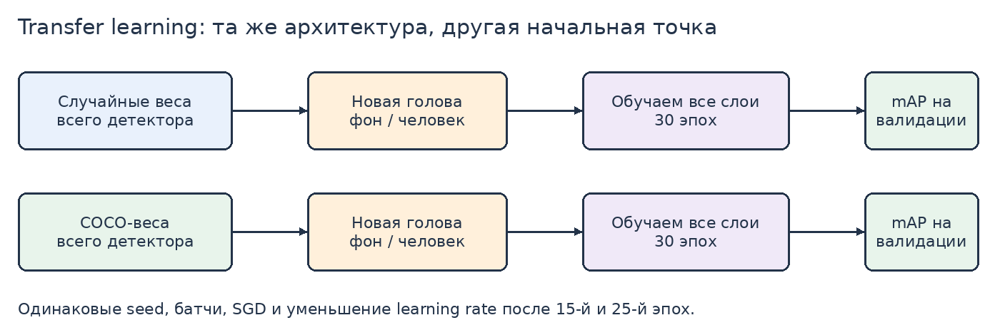


| | С нуля | С COCO-весов |
|---|---|---|
| Начальные веса | Случайные у всего детектора | Перенос весов детектора COCO |
| Выход для нашей задачи | Новая голова: фон + человек | Такая же новая голова: фон + человек |
| Что обучаем | Все слои | Все слои |

В COCO уже есть класс **person**: переносим и общие признаки, и опыт поиска людей.
Для объектов, которых не было в исходных данных, эффект может отличаться.
Переносим бэкбон, FPN, RPN и признаки RoI-головы. Последний предиктор COCO
заменяем новым предикторов классов фон/человек: число и смысл его выходов должны совпадать
с нашей разметкой. В обоих опытах новая голова начинает с одинаковых случайных весов.

Обычно при дообучении пробуют меньший learning rate для перенесённых слоёв,
чем для новой головы. Здесь у обоих запусков одинаковые SGD и learning rate, чтобы
сравнить именно начальные веса. После 15-й и 25-й эпох уменьшим learning rate
в 10 раз. Seed, порядок батчей, архитектура и число эпох одинаковы.

**Одинаковая нормализация для сравнения.** В обеих моделях используем обучаемую
`BatchNorm2d`. В готовой COCO-модели
стоит `FrozenBatchNorm`, поэтому заменим её. При замене сохраним обученные
параметры и накопленные статистики.

Чтобы сравнить предельное
качество, нужно отдельно подбирать режим и время обучения каждой модели.
При достаточном вычислительном бюджете и данных обучение с нуля тоже может дать сильное решение:
[Rethinking ImageNet Pre-training](https://arxiv.org/abs/1811.08883).
Практический пример двух способов переноса:
[PyTorch Transfer Learning Tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).


In [6]:
MODEL_CONFIG = dict(min_size=MIN_SIZE, max_size=640, box_score_thresh=0.001,
                    box_nms_thresh=0.5, box_detections_per_img=100,
                    rpn_score_thresh=0.0, rpn_pre_nms_top_n_test=150,
                    rpn_post_nms_top_n_test=150)

def make_model(pretrained=False, config=None):
    weights = FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.COCO_V1 if pretrained else None
    model = fasterrcnn_mobilenet_v3_large_320_fpn(
        weights=weights, weights_backbone=None,
        **(MODEL_CONFIG if config is None else config))
    # Одинаковая обучаемая нормализация; при COCO сохраняем её исходное состояние.
    for name, layer in list(model.backbone.named_modules()):
        if isinstance(layer, FrozenBatchNorm2d):
            norm = nn.BatchNorm2d(layer.weight.numel(), eps=layer.eps)
            norm.load_state_dict({key: getattr(layer, key) for key in
                                  ["weight", "bias", "running_mean", "running_var"]}, strict=False)
            parent, child = name.rsplit(".", 1)
            setattr(model.backbone.get_submodule(parent), child, norm)
    features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(features, num_classes=2)
    for parameter in model.parameters():
        parameter.requires_grad = True
    return model


## 4. Перекрытие рамок и NMS

Модель на выходе может выдать много рамок на один объект. Как убрать дубли
и при этом не потерять соседних людей?

Для оценки пересечения рамок можно использовать знакомую нам **IoU (Intersection over Union)** - площадь пересечения рамок, делённую на площадь их объединения.
При оценке рамок сравниваем **ответ с разметкой**, а в NMS - **ответ с другим ответом**.
**Оценка уверенности (score)** показывает, насколько модель уверена в классе объекта.
Она может уверенно распознать человека, но неточно провести границы рамки.

**NMS (non-maximum suppression)** убирает конкурирующие рамки одного класса:

1. Берём оставшуюся рамку с максимальным score и сохраняем её.
2. Удаляем остальные рамки с IoU **строго больше** порога NMS относительно выбранной.
3. Повторяем, пока кандидаты не закончатся.

NMS не усредняет координаты и не знает разметку. Для нескольких классов его
обычно применяют отдельно по классу. При низком пороге NMS может удалить даже рамку с умеренным перекрытием - вместе с дублем так можно потерять соседнего человека. При высоком пороге
сильнее перекрывающиеся рамки смогут остаться - в том числе дубли.

На GIF ниже фотография настоящая, а рамки и scores условные.
A и B обводят ближнего человека, C - соседнего, D - дальнего слева.
IoU(A,B) ≈ 0.86, IoU(A,C) = 0.60. Зелёным отмечаем сохранённые ответы,
красным - подавленные.
Анимация по очереди повторяет алгоритм для порогов 0.5, 0.7 и 0.9.


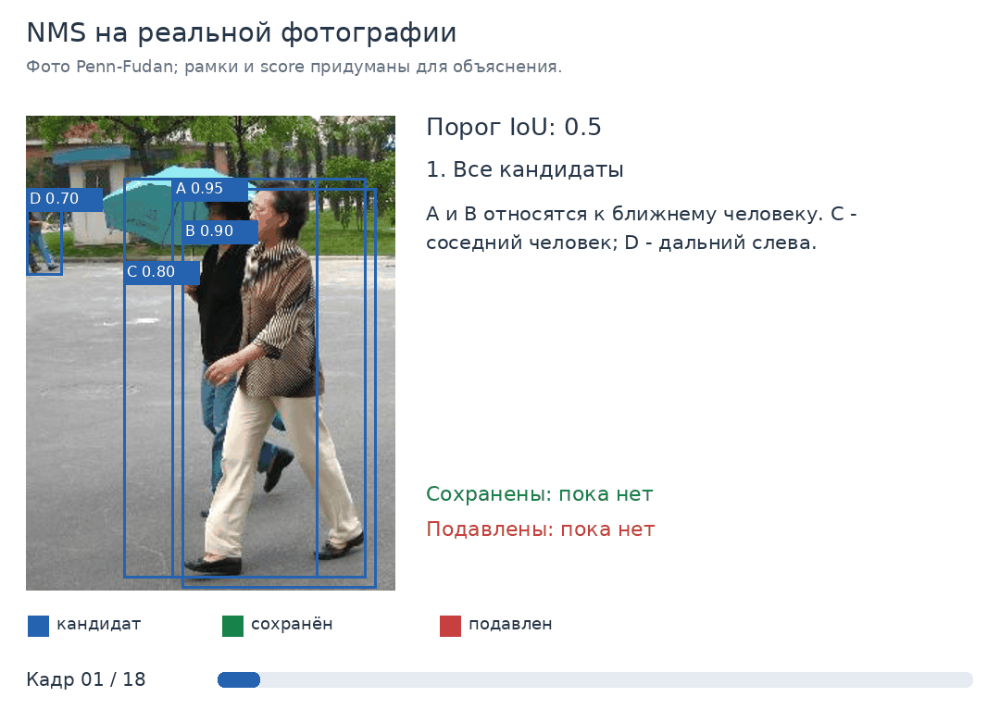


При 0.5 первой остаётся A; она подавляет и дубль B, и правильную рамку соседнего
человека C. Потом сохраняется D. При 0.7 исчезает только B. При 0.9 остаются все,
включая дубль. Поэтому в плотной толпе слишком агрессивный NMS может убирать людей.

NMS уже встроен в выбранную реализацию Faster R-CNN. Нельзя вернуть подавленную рамку простым
снижением `SHOW_SCORE`: для другого NMS нужно заново получить ответы с новой
настройкой `box_nms_thresh`. Эту настройку подбирают на валидации.
[Точное поведение torchvision.ops.nms](https://docs.pytorch.org/vision/stable/generated/torchvision.ops.nms.html).


### Влияние размера объекта на IoU

Сдвинем рамку вправо на пять пикселей. Для большого объекта это небольшая ошибка,
для маленького - заметная часть его ширины. Проверим на двух квадратах:
масштаб осей на рисунках одинаковый. Зелёная рамка - разметка, оранжевая - ответ.


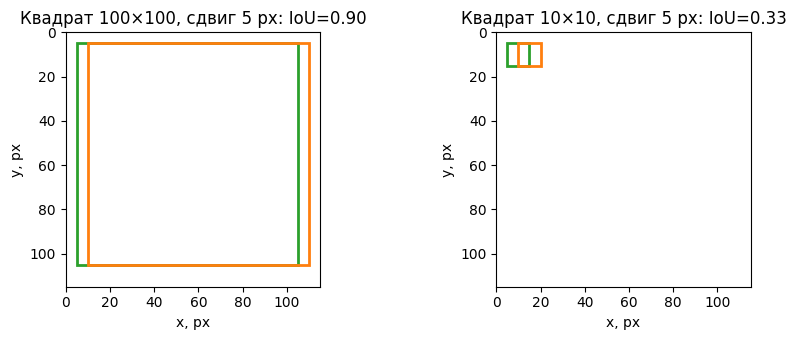

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
size_ious = []
for ax, side in zip(axes, [100, 10]):
    true_box = torch.tensor([[5., 5., 5. + side, 5. + side]])
    shifted_box = true_box + torch.tensor([5., 0., 5., 0.])
    iou = box_iou(true_box, shifted_box).item()
    size_ious.append(iou)
    draw_boxes(ax, true_box, color="tab:green")
    draw_boxes(ax, shifted_box, color="tab:orange")
    ax.set(xlim=(0, 115), ylim=(115, 0), aspect="equal",
           title=f"Квадрат {side}×{side}, сдвиг 5 px: IoU={iou:.2f}", xlabel="x, px", ylabel="y, px")
plt.tight_layout(); plt.show()


Для квадрата 100×100 IoU ≈ 0.90, а для 10×10 - только 0.33.
Одинаковая ошибка координат сильнее бьёт по маленьким объектам. У дальнего пешехода к этому
добавляется ещё и нехватка деталей на фотографии.
Теперь договоримся, какое совпадение с GT считать находкой и как оценить весь набор ответов.


## 5. Оценка набора рамок: AP

Для **AP (Average Precision)** важно, чтобы правильные ответы стояли выше ошибок
в списке, отсортированном по score. Но сначала нужно решить, какие рамки считать
правильными. Для этого сопоставим ответы модели с разметкой по IoU.
На одном изображении может быть несколько объектов, а на один объект детектор
может выдать несколько ответов.
Совпавший ответ - **TP (true positive)**, ответ без подходящей пары -
**FP (false positive)**, а не найденный GT - **FN (false negative)**.
Precision = TP/(TP+FP): какая доля ответов верна. Recall = TP/(TP+FN):
какая доля размеченных объектов найдена.
Для одного класса и фиксированного порога IoU, например 0.50:

1. Внутри каждого изображения рассматриваем ответы по убыванию score.
2. Ответ сопоставляем с ещё не занятой рамкой разметки (GT) того же класса при IoU ≥ 0.50;
   из подходящих выбираем рамку с наибольшим IoU. Это TP.
3. Ответ без пары - FP: дубль, фон, неправильный класс или неточная рамка.
   GT без пары - пропуск. Сопоставлять рамки из разных фотографий нельзя.
4. Объединяем результаты **всех изображений** для этого класса и снова сортируем
   по score. Накопленные TP/FP дают precision и recall при разных порогах score.
5. Из precision–recall получаем AP. Это не средняя AP отдельных фотографий.

В примере ниже нет **crowd** (группы объектов без разделения на экземпляры)
и **ignore** (объекты, исключённые из оценки). Эти случаи в полной оценке
обрабатывает **COCOeval** - официальная реализация метрики COCO.


### Матчинг: сопоставление ответов с разметкой

Сопоставление предсказанных рамок с GT называют **матчингом (matching)**.

Зелёный пунктир - правильные рамки GT. В примере три
объекта и четыре ответа одного класса. Два ответа не могут получить зачёт
за одного и того же человека.

Здесь намеренно не применяем NMS: посмотрим, как метрика обрабатывает дубль.
Идём по убыванию score и ищем каждому ответу ещё не занятую рамку GT
с IoU ≥ 0.50.


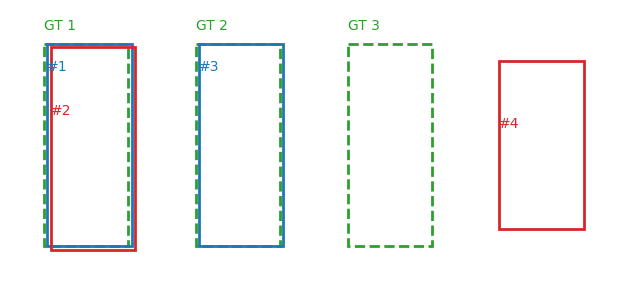

| Ответ | Score | Лучший IoU | Результат |
|---|---|---|---|
| #1 | 0.95 | 0.92 | TP: найден GT 1 |
| #2 | 0.90 | 0.83 | FP: дубль |
| #3 | 0.80 | 0.92 | TP: найден GT 2 |
| #4 | 0.70 | 0.00 | FP: фон |

TP=2, FP=2, FN=1; precision=0.50, recall=0.67


In [8]:
match_gt = torch.tensor([[10., 10., 35., 70.], [55., 10., 80., 70.], [100., 10., 125., 70.]])
match_boxes = torch.tensor([[11., 10., 36., 70.], [12., 11., 37., 71.],
                            [56., 10., 81., 70.], [145., 15., 170., 65.]])
match_scores = torch.tensor([0.95, 0.90, 0.80, 0.70])
ious = box_iou(match_boxes, match_gt)
used = set()
match_rows = []
match_tp = []
fig, ax = plt.subplots(figsize=(11, 3))
draw_boxes(ax, match_gt)
for patch in ax.patches:
    patch.set_linestyle("--")
for j, box in enumerate(match_gt):
    ax.text(float(box[0]), 6, f"GT {j+1}", color="tab:green")
for i in match_scores.argsort(descending=True).tolist():
    available = [j for j in range(len(match_gt)) if j not in used and ious[i, j] >= 0.5]
    if available:
        j = max(available, key=lambda j: float(ious[i, j]))
        used.add(j)
        status, color = f"TP: найден GT {j+1}", "tab:blue"
    else:
        status = "FP: дубль" if ious[i].max() >= 0.5 else "FP: фон"
        color = "tab:red"
    draw_boxes(ax, match_boxes[i:i+1], color=color)
    x, y = match_boxes[i, :2].tolist()
    ax.text(x, y + 8 + 12 * (i % 2), f"#{i+1}", color=color)
    match_tp.append(int(bool(available)))
    match_rows.append([f"#{i+1}", f"{match_scores[i]:.2f}", f"{ious[i].max():.2f}", status])
ax.set(xlim=(0, 180), ylim=(80, 0), aspect="equal"); ax.axis("off")
plt.tight_layout(); plt.show()
from IPython.display import Markdown, display
header = "| Ответ | Score | Лучший IoU | Результат |\n|---|---|---|---|\n"
display(Markdown(header + "\n".join("| " + " | ".join(row) + " |" for row in match_rows)))
tp, fp, fn = len(used), len(match_boxes) - len(used), len(match_gt) - len(used)
print(f"TP={tp}, FP={fp}, FN={fn}; precision={tp/(tp+fp):.2f}, recall={tp/(tp+fn):.2f}")


Ответ #1 занял GT 1. У #2 тоже хороший IoU, но это дубль - второго зачёта нет.
Ответ #3 нашёл GT 2, #4 попал на фон, а GT 3 остался без ответа.
Получилось две находки, две лишние рамки и один пропуск: precision = 2/4,
recall = 2/3. Число предсказаний само по себе ничего не говорит о числе найденных объектов.


### От TP/FP к одному числу

Для ответов #1/#2/#3/#4 нашего примера последовательность - **TP, FP, TP, FP**.
После первого ответа precision=1, recall=1/3; после второго - 1/2 и 1/3;
после третьего - 2/3 и 2/3; после четвёртого - 1/2 и 2/3.

Возьмём 101 значение recall: 0.00, 0.01, …, 1.00. Для каждого найдём лучшую
precision среди точек с таким же или большим recall. Если нужного recall мы так
и не достигли, запишем ноль. Это правило называют **интерполяцией precision**.
Среднее этих 101 значений и будет AP по правилам COCO.

Например, для recall = 0.5 в нашем примере получим precision = 2/3.
А для recall = 0.8 запишем ноль: модель нашла только два объекта из трёх.

$$AP_{\tau} = \frac{1}{101}\sum_{r \in \{0,.01,\ldots,1\}} p_{interp}(r),
\qquad p_{interp}(r)=\max_{r'\ge r} p(r').$$

Здесь $\tau$ - выбранный порог IoU. Точки на графике покажут накопленные
precision/recall, линии - интерполированную precision для расчёта AP.

Посчитаем этот маленький пример. Во втором варианте повысим score ответа
на фоне (#4), чтобы он оказался первым. Боксы и число находок те же,
но порядок ответов хуже. Полную рабочую метрику будет считать COCOeval.

На GIF повторим расчёт на фотографии: **GT и ответы условные**, это не исходная
разметка Penn-Fudan. Геометрия другая, но последовательность TP/FP та же:
#1 находит первый GT, #2 дублирует его, #3 находит второй, #4 попадает на фон.
Вторая часть GIF меняет только score фоновой рамки на 0.99. Счётчик и полоска
показывают прогресс всего цикла. После анимации проверим оба значения AP кодом.


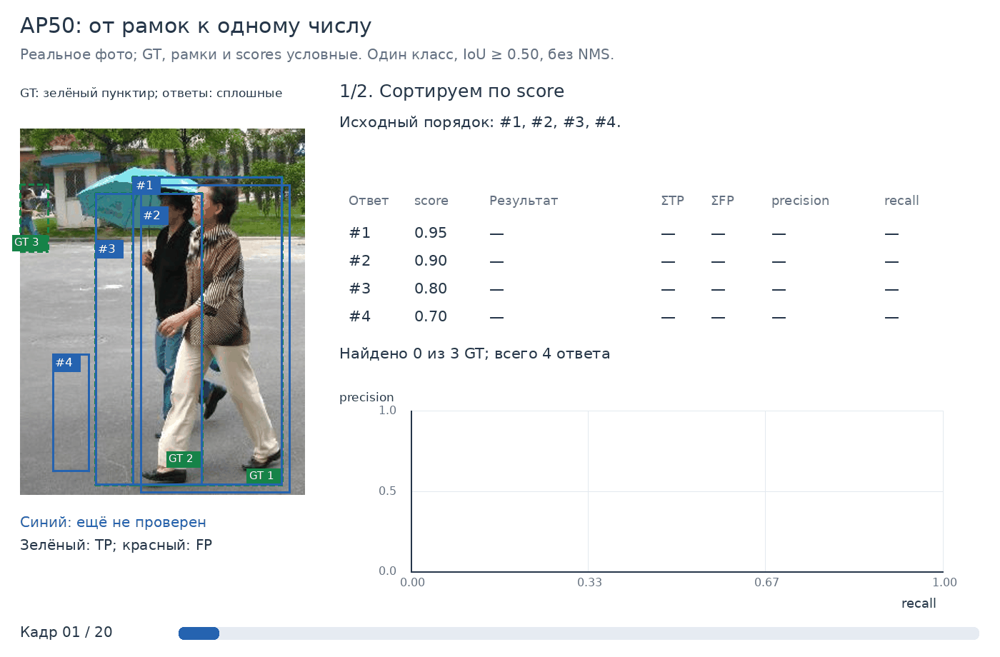


Исходный порядок precision: [1.    0.5   0.667 0.5  ] recall: [0.333 0.333 0.667 0.667]
Фон с самым высоким score precision: [0.    0.5   0.333 0.5  ] recall: [0.    0.333 0.333 0.667]


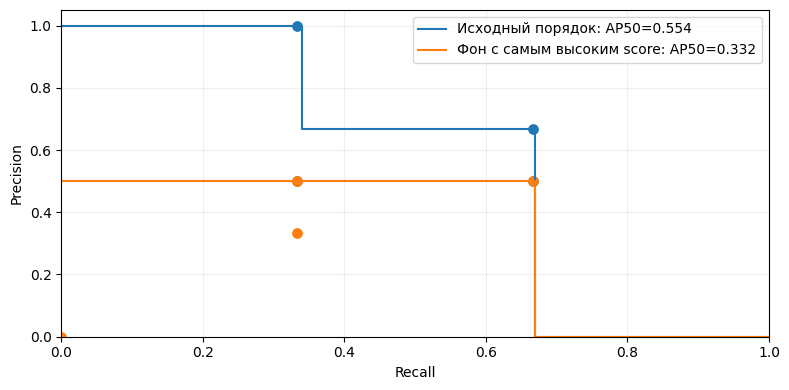

In [9]:
recall_grid = np.linspace(0, 1, 101)
ap_examples = []
fig, ax = plt.subplots(figsize=(8, 4))
for flags, title in [(match_tp, "Исходный порядок"), ([0, 1, 0, 1], "Фон с самым высоким score")]:
    cumulative_tp = np.cumsum(flags)
    precision = cumulative_tp / np.arange(1, len(flags) + 1)
    recall = cumulative_tp / len(match_gt)
    sampled = np.array([precision[recall >= r].max() if np.any(recall >= r) else 0.
                        for r in recall_grid])
    ap = float(sampled.mean())
    ap_examples.append(ap)
    line, = ax.step(recall_grid, sampled, where="post", label=f"{title}: AP50={ap:.3f}")
    ax.scatter(recall, precision, color=line.get_color(), s=45)
    print(title, "precision:", precision.round(3), "recall:", recall.round(3))
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.05))
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()


В первом порядке AP50 ≈ 0.554, во втором ≈ 0.332. Финальные precision=0.5 и
recall=2/3 совпадают, но ранний уверенный ответ на фоне испортил ранжирование.
Правее recall=2/3 интерполированная precision для AP равна нулю: третий объект так и не найден.
AP не равна средней IoU и не определяется одной выбранной точкой score.

**AP50** использует IoU=0.50. При более строгом пороге часть неточных рамок станет
FP, а соответствующие объекты - пропусками. Для **mAP (mean Average Precision) @[0.50:0.95]** повторяем
оценку при десяти IoU (0.50, 0.55, …, 0.95) и усредняем по ним и классам.
У нас один класс; число фотографий не является числом слагаемых в этом среднем.

В рабочей оценке используем TorchMetrics с официальным COCOeval:
area=all (объекты всех размеров), maxDets=[1,10,100]; основная AP использует
максимум 100 ответов на изображение.
Порог `SHOW_SCORE` применяется только к рисункам. Для mAP передаём все возвращённые
детектором scores, включая слабые выше внутреннего порога 0.001.
В отличие от порога NMS, порог IoU метрики сравнивает ответ именно с разметкой.
[Протокол и интерполяция COCOeval](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py).


## 6. Обучаем обе модели

Теперь нужно научить сеть давать правильные классы и координаты. Что считать
обучающим примером: опорную рамку, предложенную область или итоговую рамку после NMS?
В Faster R-CNN есть два этапа, и для каждого мы готовим свои примеры.

### Положительные и отрицательные примеры

При обучении каждому кандидату назначаем метку. **Положительный пример**
соответствует конкретному объекту GT: сеть должна определить его класс и уточнить
координаты рамки. Для **отрицательного примера** правильный класс - «фон»;
координаты для него не обучаем.

Для RPN классов всего два: «объект» и «фон». RoI-голова уже различает
конкретные классы объектов.

Это метки для обучения, а не знак score и не «хорошее / плохое» предсказание.
Отрицательная область может задевать человека: важно, достаточно ли совпадение с GT.

В нашем torchvision-варианте правила такие:

| Кандидат | Положительный | Отрицательный | Не участвует в лоссе |
|---|---|---|---|
| Опорная рамка для RPN | Лучший IoU с GT ≥ 0.7; также действует правило лучшего совпадения с GT | IoU < 0.3, если не выбрана правилом лучшего совпадения | Остальные опорные рамки с 0.3 ≤ IoU < 0.7 |
| Предложенная область для RoI-головы | Лучший IoU с GT ≥ 0.5 | IoU < 0.5 | Промежутка между порогами здесь нет |

Правило лучшего совпадения дополнительно помечает лучшие опорные рамки для каждого GT
как положительные, даже если IoU ниже 0.7. Так объект с неудобной геометрией
тоже может дать положительные примеры. Из кандидатов затем берут подвыборку
положительных и отрицательных, чтобы многочисленный фон не определял весь лосс.

Например, при IoU 0.8 и опорная рамка, и предложенная область положительны;
при 0.1 обычно отрицательны. При 0.6 опорная рамка обычно игнорируется,
а предложенная область уже положительна.
Пороги относятся к **обучению**, а не к NMS и не к зачёту TP в метрике.

### От опорных рамок к лоссам двух голов

**Логиты** - выходные числа до sigmoid/softmax. Классификационные функции потерь
получают именно логиты: нужное преобразование уже находится внутри лосса.

1. **RPN** предсказывает вероятность класса «объект» и смещения для опорных рамок.
   Метки 1/0 и целевые смещения получаем из GT. Оба лосса RPN считаем
   по исходным предсказаниям **до NMS RPN**.
2. Для следующей головы смещения превращаются в координаты предложенных областей,
   кандидаты фильтруются и проходят **NMS RPN - при обучении и при инференсе**.
3. Во время обучения к предложенным областям добавляют GT-рамки, сопоставляют области с GT
   и выбирают положительные/отрицательные RoI. Положительной RoI назначают
   класс её GT (у нас «человек»), отрицательной - класс «фон».
4. RoI-голова предсказывает классы и смещения. Её два лосса считаются
   **до финальной NMS**. При `train()` финальная NMS вообще не вызывается.

Несколько положительных опорных рамок или RoI могут относиться к одному GT - это
нормальные обучающие примеры. В отличие от AP, здесь не надо объявлять второй
такой пример дублем и превращать его в отрицательный.

На схеме каждый лосс подписан у того выхода, который он обучает.


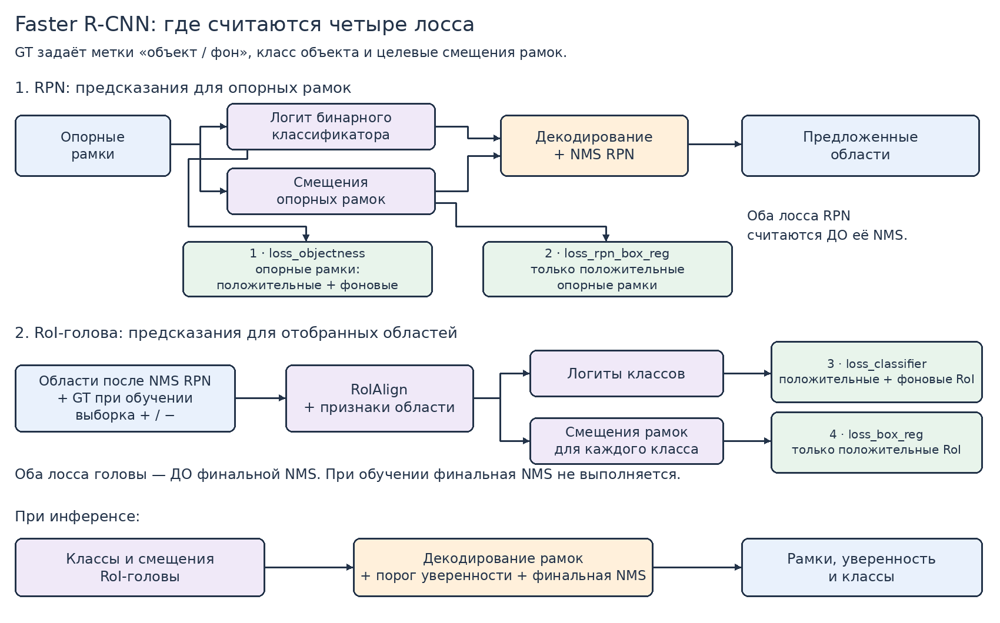


### Что штрафует каждый лосс

1. **`loss_objectness` - есть ли в опорной рамке объект?** Бинарная кросс-энтропия сравнивает
   оценку RPN с меткой 1 у положительной опорной рамки и 0 у отрицательной.
   Для одного положительного примера вероятность 0.1 даёт штраф −log(0.1) ≈ 2.30,
   а 0.9 - всего 0.105. Неверная уверенность стоит дороже.
2. **`loss_rpn_box_reg` - как сдвинуть опорную рамку к GT?** По GT вычисляем,
   насколько нужно сдвинуть центр рамки и изменить её ширину и высоту.
   Лосс сравнивает эти четыре поправки с предсказанными.
   Здесь участвуют **только положительные опорные рамки**. Для фона нет рамки-цели.
3. **`loss_classifier` - какой класс у RoI?** Кросс-энтропия штрафует неверный класс
   выбранной области. У положительной RoI это класс GT, у отрицательной - фон.
   RPN решала бинарную классификацию без различения типов объектов;
   эта голова определяет конкретный класс объекта.
4. **`loss_box_reg` - как уточнить предложенную область?** Снова сравниваем
   предсказанные и целевые поправки, но теперь относительно RoI. Для каждой
   **положительной RoI** берём поправки, предсказанные для её правильного класса,
   и сравниваем с целевыми. Отрицательные RoI в этот лосс не входят: для фона
   нет правильной рамки.

Оба координатных лосса используют **Smooth L1**. При маленькой ошибке этот лосс
похож на квадрат ошибки, а при большой растёт линейно. Поэтому отдельные крупные
ошибки меньше влияют на лосс, чем при MSE. Сравниваются
**смещения относительно опорной рамки или предложенной области**, а не сырые координаты в пикселях
и не IoU готовых рамок. Нулевые смещения оставили бы исходную рамку на месте.

В `train_epoch` складываем четыре лосса и вызываем `backward()`. Каждый лосс
обучает свою голову, а общий бэкбон получает градиенты от обеих голов.

При этом лоссы RoI-головы не обучают RPN через координаты предложенных областей:
перед отбором областей предсказания RPN отсоединяются от графа с помощью `detach`.
Сама RPN обучается по двум собственным лоссам, рассчитанным до её NMS.

При `eval()` получаем уже готовые рамки, оценки уверенности и классы
после постобработки, в координатах исходной фотографии.

Реализация: [RPN](https://github.com/pytorch/vision/blob/main/torchvision/models/detection/rpn.py),
[RoIHeads / fastrcnn_loss](https://github.com/pytorch/vision/blob/main/torchvision/models/detection/roi_heads.py)
и [пороги сопоставления Faster R-CNN](https://github.com/pytorch/vision/blob/main/torchvision/models/detection/faster_rcnn.py).


In [10]:
def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, count = 0.0, 0
    for images, targets in loader:
        images = [image.to(DEVICE) for image in images]
        targets = [{key: value.to(DEVICE) for key, value in t.items()} for t in targets]
        optimizer.zero_grad()
        loss = sum(model(images, targets).values())
        if not torch.isfinite(loss):
            raise ValueError("Loss стал NaN/Inf: проверьте рамки и learning rate")
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(images)
        count += len(images)
    return total_loss / count

@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", backend="pycocotools",
                                  max_detection_thresholds=[1, 10, 100])
    for images, targets in loader:
        predictions = model([image.to(DEVICE) for image in images])
        predictions = [{key: value.cpu() for key, value in p.items()} for p in predictions]
        metric.update(predictions, targets)
    result = metric.compute()
    return float(result["map"]), float(result["map_50"])


Для каждого старта заново задаём seed, создаём DataLoader, модель и оптимизатор.
Сохраняем лучшую эпоху каждой модели по mAP на валидации. Затем по той же метрике
выбираем одну из двух моделей для дальнейших рисунков и финальной оценки на тестовой выборке.
30 эпох сравниваются с 30. После 15-й и 25-й эпох уменьшаем learning rate
в 10 раз. Время измеряется отдельно; выбирается лучшая эпоха, а не обязательно последняя.
Повторный запуск ячейки начнёт оба обучения сначала.


In [11]:
results = []
for tag, title, pretrained in [("scratch", "С нуля", False), ("pretrained", "COCO → Penn-Fudan", True)]:
    set_seed(SEED)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn,
                              num_workers=0, generator=torch.Generator().manual_seed(SEED))
    model = make_model(pretrained=pretrained).to(DEVICE)
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.9, weight_decay=0.0005)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=LR_MILESTONES, gamma=0.1)
    history = []
    best_map, best_ap50, best_epoch = -1., 0., 0
    path = WORK / f"{tag}.pt"
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        epoch_lr = optimizer.param_groups[0]["lr"]
        train_loss = train_epoch(model, train_loader, optimizer)
        val_map, val_ap50 = evaluate(model, val_loader)
        history.append(dict(epoch=epoch, loss=train_loss, map=val_map, ap50=val_ap50, lr=epoch_lr))
        if val_map > best_map:
            best_map, best_ap50, best_epoch = val_map, val_ap50, epoch
            torch.save({"model": model.state_dict(), "architecture": "fasterrcnn_mobilenet_v3_large_320_fpn",
                        "config": MODEL_CONFIG, "class_names": {0: "background", 1: "person"},
                        "initial_weights": "COCO_V1" if pretrained else "random", "label": title,
                        "normalization": "BatchNorm2d", "seed": SEED, "epoch": epoch, "val_map": val_map,
                        "training": {"epochs": EPOCHS, "lr": LEARNING_RATE, "milestones": LR_MILESTONES},
                        "preprocessing": {"input": "RGB float32 [0,1]", "external_resize": None,
                                          "image_mean": model.transform.image_mean, "image_std": model.transform.image_std},
                        "splits": {"train": train_names, "val": val_names, "test": test_names}}, path)
        print(f"{title}, {epoch}/{EPOCHS}: loss={train_loss:.3f}, val mAP={val_map:.3f}, AP50={val_ap50:.3f}, lr={epoch_lr:g}")
        scheduler.step()
    results.append(dict(tag=tag, label=title, map=best_map, ap50=best_ap50, epoch=best_epoch,
                        seconds=time.perf_counter()-started, path=str(path), history=history))
    del model, optimizer
winner = max(results, key=lambda row: row["map"])
checkpoint_path = WORK / "person_detector.pt"
checkpoint_path.write_bytes(Path(winner["path"]).read_bytes())
print("Выбрана модель:", winner["label"], "| лучшая эпоха:", winner["epoch"])

(WORK / "training_comparison.json").write_text(json.dumps(
    {"seed": SEED, "epochs": EPOCHS, "device": str(DEVICE), "results": results},
    ensure_ascii=False, indent=2), encoding="utf-8")


С нуля, 1/30: loss=1.111, val mAP=0.006, AP50=0.024, lr=0.005
С нуля, 2/30: loss=0.723, val mAP=0.036, AP50=0.130, lr=0.005
С нуля, 3/30: loss=0.504, val mAP=0.005, AP50=0.022, lr=0.005
С нуля, 4/30: loss=0.461, val mAP=0.063, AP50=0.285, lr=0.005
С нуля, 5/30: loss=0.435, val mAP=0.121, AP50=0.437, lr=0.005
С нуля, 6/30: loss=0.408, val mAP=0.199, AP50=0.648, lr=0.005
С нуля, 7/30: loss=0.400, val mAP=0.115, AP50=0.404, lr=0.005
С нуля, 8/30: loss=0.389, val mAP=0.176, AP50=0.663, lr=0.005
С нуля, 9/30: loss=0.381, val mAP=0.203, AP50=0.610, lr=0.005
С нуля, 10/30: loss=0.402, val mAP=0.193, AP50=0.587, lr=0.005
С нуля, 11/30: loss=0.364, val mAP=0.244, AP50=0.672, lr=0.005
С нуля, 12/30: loss=0.372, val mAP=0.227, AP50=0.705, lr=0.005
С нуля, 13/30: loss=0.331, val mAP=0.268, AP50=0.729, lr=0.005
С нуля, 14/30: loss=0.337, val mAP=0.252, AP50=0.756, lr=0.005
С нуля, 15/30: loss=0.315, val mAP=0.279, AP50=0.724, lr=0.005
С нуля, 16/30: loss=0.292, val mAP=0.302, AP50=0.780, lr=0.0005


100%|██████████| 74.2M/74.2M [00:00<00:00, 182MB/s]


COCO → Penn-Fudan, 1/30: loss=0.548, val mAP=0.458, AP50=0.907, lr=0.005
COCO → Penn-Fudan, 2/30: loss=0.270, val mAP=0.570, AP50=0.947, lr=0.005
COCO → Penn-Fudan, 3/30: loss=0.207, val mAP=0.560, AP50=0.931, lr=0.005
COCO → Penn-Fudan, 4/30: loss=0.174, val mAP=0.634, AP50=0.965, lr=0.005
COCO → Penn-Fudan, 5/30: loss=0.159, val mAP=0.647, AP50=0.957, lr=0.005
COCO → Penn-Fudan, 6/30: loss=0.142, val mAP=0.648, AP50=0.941, lr=0.005
COCO → Penn-Fudan, 7/30: loss=0.131, val mAP=0.638, AP50=0.966, lr=0.005
COCO → Penn-Fudan, 8/30: loss=0.113, val mAP=0.625, AP50=0.954, lr=0.005
COCO → Penn-Fudan, 9/30: loss=0.106, val mAP=0.651, AP50=0.957, lr=0.005
COCO → Penn-Fudan, 10/30: loss=0.094, val mAP=0.655, AP50=0.960, lr=0.005
COCO → Penn-Fudan, 11/30: loss=0.094, val mAP=0.641, AP50=0.969, lr=0.005
COCO → Penn-Fudan, 12/30: loss=0.092, val mAP=0.650, AP50=0.959, lr=0.005
COCO → Penn-Fudan, 13/30: loss=0.089, val mAP=0.654, AP50=0.950, lr=0.005
COCO → Penn-Fudan, 14/30: loss=0.084, val mAP=0

11418

| Старт | Лучшая эпоха | Val mAP | AP50 той же эпохи | Время, мин |
|---|---:|---:|---:|---:|
| С нуля | 19 | 0.311 | 0.809 | 3.7 |
| COCO → Penn-Fudan | 15 | 0.690 | 0.954 | 3.5 |

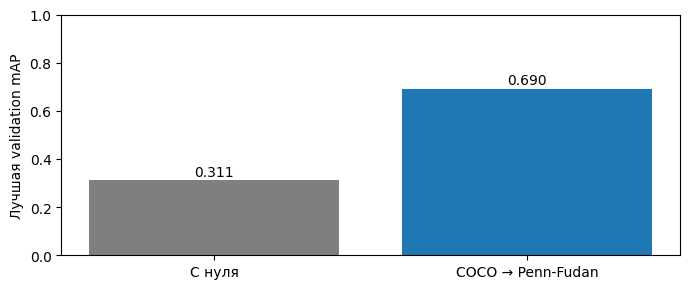

In [12]:
header = "| Старт | Лучшая эпоха | Val mAP | AP50 той же эпохи | Время, мин |\n|---|---:|---:|---:|---:|\n"
rows = [f"| {r['label']} | {r['epoch']} | {r['map']:.3f} | {r['ap50']:.3f} | {r['seconds']/60:.1f} |" for r in results]
display(Markdown(header + "\n".join(rows)))
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([r["label"] for r in results], [r["map"] for r in results], color=["tab:gray", "tab:blue"])
ax.set(ylabel="Лучшая validation mAP", ylim=(0, 1))
for i, row in enumerate(results):
    ax.text(i, row["map"] + 0.02, f"{row['map']:.3f}", ha="center")
plt.tight_layout(); plt.show()


В сохранённом запуске на **Tesla T4** модель с нуля получила лучшую mAP на валидации **0.311** на 19-й эпохе, а дообучение - **0.690** на 15-й. AP50 в таблице
относится к тем же эпохам.

Дальше используем чекпоинт дообученной модели с 15-й эпохи. Модель уже выбрана
по валидации. Тестовую выборку проверим в конце урока.


## 7. Разбираем ошибки выбранной модели

Загрузим выбранные веса в новую модель. Слева - зелёная разметка,
справа - оранжевые ответы при `SHOW_SCORE`. Начнём с трёх фиксированных
фотографий валидационной выборки: они помогут сравнить изменения модели в будущих опытах.


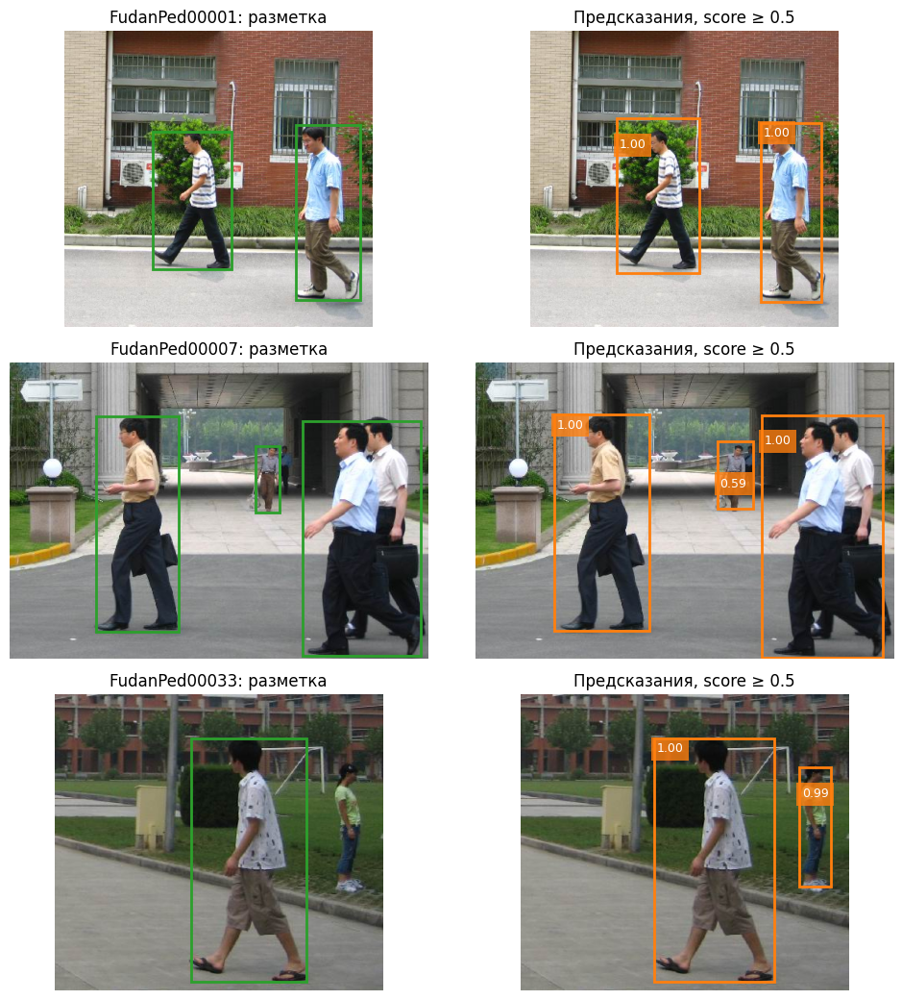

In [13]:
@torch.inference_mode()
def predict(model, image):
    model.eval()
    answer = model([image_tensor(image).to(DEVICE)])[0]
    return {key: value.cpu() for key, value in answer.items()}

def show_predictions(model, names, threshold=0.5):
    fig, axes = plt.subplots(len(names), 2, figsize=(10, 3.5 * len(names)), squeeze=False)
    for row, name in zip(axes, names):
        image, target = read_example(name)
        answer = predict(model, image)
        shown = answer["scores"] >= threshold
        for ax in row:
            ax.imshow(image); ax.axis("off")
        draw_boxes(row[0], target["boxes"])
        draw_boxes(row[1], answer["boxes"][shown], answer["scores"][shown], color="tab:orange")
        row[0].set_title(f"{name}: разметка")
        row[1].set_title(f"Предсказания, score ≥ {threshold}")
    plt.tight_layout(); plt.show()

saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
selected_model = make_model(config=saved["config"]).to(DEVICE)
selected_model.load_state_dict(saved["model"])
selected_model.transform.image_mean = saved["preprocessing"]["image_mean"]
selected_model.transform.image_std = saved["preprocessing"]["image_std"]
show_predictions(selected_model, ["FudanPed00001", "FudanPed00007", "FudanPed00033"], SHOW_SCORE)


На `FudanPed00001` сеть нашла обоих людей, хотя границы рамок не везде совпали
с GT. На `FudanPed00007` дальний человек тоже найден, но его score ≈ 0.59,
заметно ниже уверенности в крупных людях. Справа две близкие фигуры оказались
в одной рамке - так же устроена разметка этого кадра.

На `FudanPed00033` виден другой случай: у маленького человека справа нет GT-рамки,
но модель его выделила. Для метрики это лишний ответ. Это пример того, как важно проверять разметку и уверенные "неправильные" ответы модели.

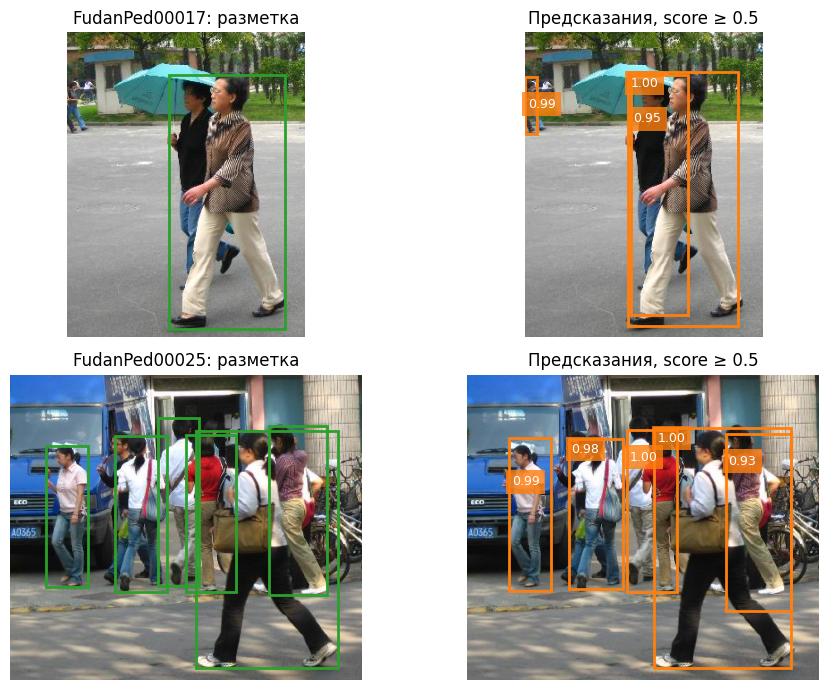

In [14]:
show_predictions(selected_model, ["FudanPed00017", "FudanPed00025"], SHOW_SCORE)


На `FudanPed00017` показаны три ответа при одной GT-рамке: есть дополнительный
ответ на дальнего человека слева и пересекающиеся рамки в центре.
Разбирайте, к каким объектам и GT относится каждый ответ.

На `FudanPed00025` видно пять ответов при шести GT. Но при IoU ≥ 0.5 из этих
**показанных** рамок зачтутся только четыре: у одной лучший IoU ≈ 0.494,
чуть ниже порога. Число оранжевых рамок не равно числу найденных объектов.

Ошибки при обучении подсказывают следующие эксперименты:

- Теряется маленький человек → проверить масштаб и размер входа.
- Остались дубли → посмотреть score и NMS, не удаляя соседних людей.
- Ответ выглядит правильным, но даёт FP → проверить IoU и полноту GT.

Дальше посмотрим, что можно поменять без нового обучения: исходные веса,
порог показа и размер входа.


## 8. Диагностика без нового обучения

### Исходная COCO-модель и дообученный детектор

COCO-модель уже обучена находить людей. Покажем её исходные ответы рядом с выбранной
моделью на двух фотографиях валидационной выборки. В исходной сети сохраняем
всю COCO-голову и выбираем только класс `person`.
Размер входа, NMS и порог показа одинаковые. На рисунках сравните
ответы на дальних людях и на тесной группе.


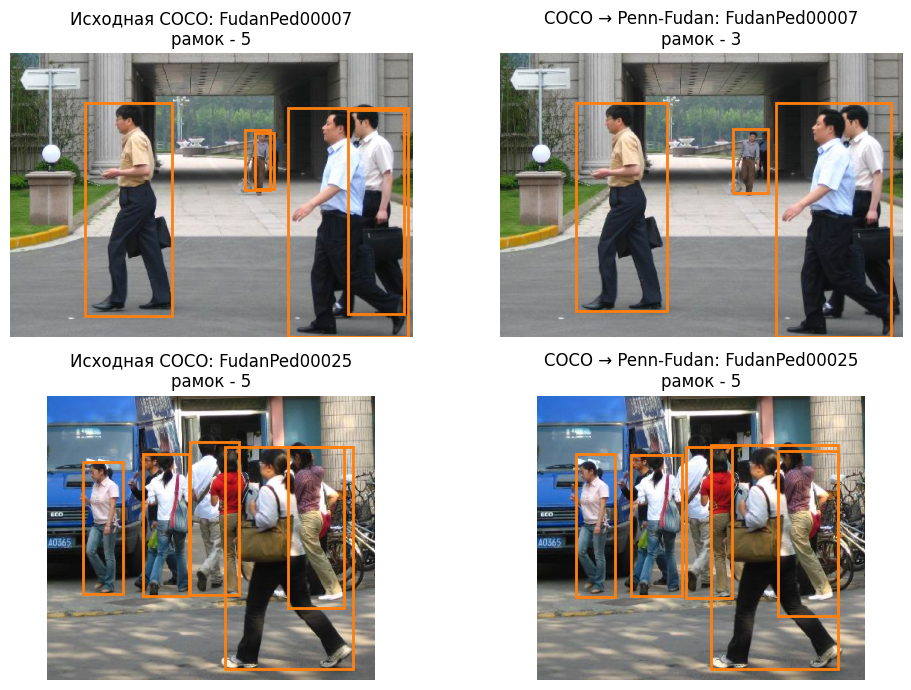

In [15]:
coco_weights = FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.COCO_V1
coco_model = fasterrcnn_mobilenet_v3_large_320_fpn(
    weights=coco_weights, weights_backbone=None, **saved["config"]).to(DEVICE).eval()
person_id = coco_weights.meta["categories"].index("person")
comparison_names = ["FudanPed00007", "FudanPed00025"]
comparison_counts = []
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, name in zip(axes, comparison_names):
    image, _ = read_example(name)
    counts = []
    for ax, detector, class_id, title in zip(
            row, [coco_model, selected_model], [person_id, 1], ["Исходная COCO", saved["label"]]):
        prediction = predict(detector, image)
        shown = (prediction["labels"] == class_id) & (prediction["scores"] >= SHOW_SCORE)
        counts.append(int(shown.sum()))
        ax.imshow(image); ax.axis("off")
        draw_boxes(ax, prediction["boxes"][shown], color="tab:orange")
        ax.set_title(f"{title}: {name}\nрамок - {counts[-1]}")
    comparison_counts.append(counts)
plt.tight_layout(); plt.show()
del coco_model


На `FudanPed00007` исходная COCO-модель дала пять рамок, дообученная - три.
У дальнего человека исчез дубль, но справа две близкие фигуры объединились
в одну рамку. На `FudanPed00025` у обеих моделей по пять ответов, однако границы
различаются. Поэтому сравнивайте соответствие объектам и GT, а не только число рамок.

Перенос дал полезный старт ещё до нашего обучения; дообучение затем приспособило
детектор к новой разметке.

### Порог показа ответов

Один раз запустим детектор на фотографии и покажем результат с тремя порогами:
0.2, 0.5 и 0.8.

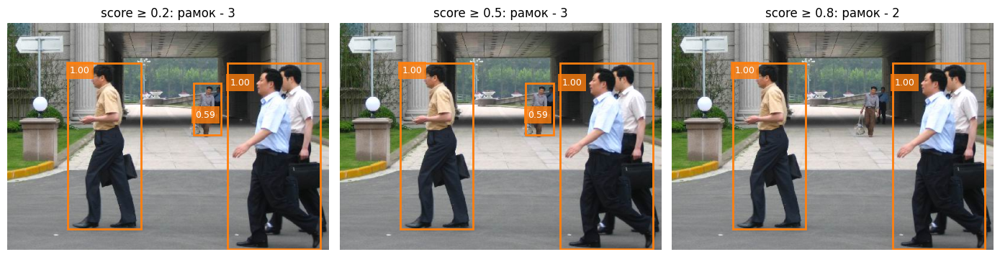

In [16]:
threshold_image, _ = read_example("FudanPed00007")
threshold_answer = predict(selected_model, threshold_image)
threshold_counts = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, threshold in zip(axes, [0.2, 0.5, 0.8]):
    shown = threshold_answer["scores"] >= threshold
    threshold_counts.append(int(shown.sum()))
    ax.imshow(threshold_image); ax.axis("off")
    draw_boxes(ax, threshold_answer["boxes"][shown], threshold_answer["scores"][shown], color="tab:orange")
    ax.set_title(f"score ≥ {threshold}: рамок - {threshold_counts[-1]}")
plt.tight_layout(); plt.show()


При порогах 0.2 и 0.5 остаются три рамки, при 0.8 - две: исчезает дальний
человек со score ≈ 0.59. Его координаты не уточнились - ответ просто удалён.
Порог удобен для показа, но более «чистая» картинка может скрывать пропуск.
При подсчёте AP мы не применяем `SHOW_SCORE`, чтобы сохранить ранжирование ответов.


### Размер входа: качество и скорость

Увеличим внутренний размер входа с 320 до 640 по короткой стороне,
не меняя веса. Ограничение длинной стороны тоже увеличим вдвое.


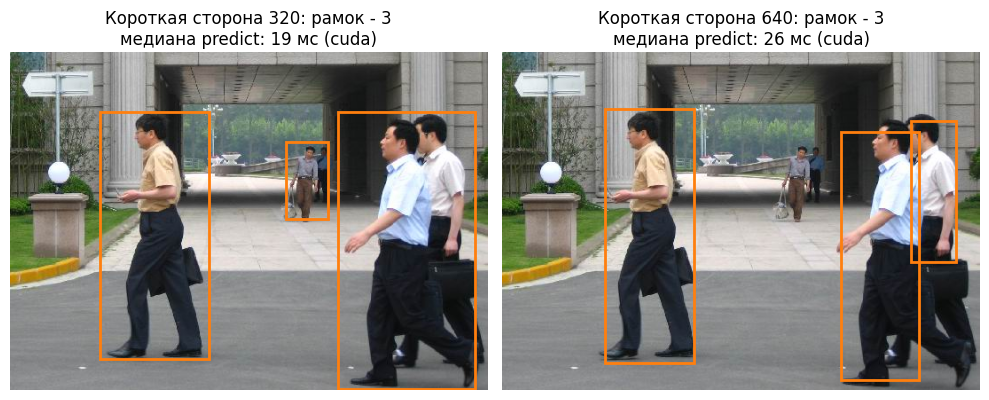

In [17]:
resolution_image, _ = read_example("FudanPed00007")
old_min, old_max = selected_model.transform.min_size, selected_model.transform.max_size
resolution_results = []
try:
    for side in [320, 640]:
        selected_model.transform.min_size = (side,)
        selected_model.transform.max_size = 2 * side
        predict(selected_model, resolution_image)  # прогрев
        durations = []
        for _ in range(3):
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            started = time.perf_counter()
            prediction = predict(selected_model, resolution_image)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            durations.append(time.perf_counter() - started)
        resolution_results.append((side, prediction, float(np.median(durations))))
finally:
    selected_model.transform.min_size, selected_model.transform.max_size = old_min, old_max
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (side, prediction, seconds) in zip(axes, resolution_results):
    shown = prediction["scores"] >= SHOW_SCORE
    ax.imshow(resolution_image); ax.axis("off")
    draw_boxes(ax, prediction["boxes"][shown], color="tab:orange")
    ax.set_title(f"Короткая сторона {side}: рамок - {int(shown.sum())}\nмедиана predict: {seconds*1000:.0f} мс ({DEVICE.type})")
plt.tight_layout(); plt.show()


При 320 и 640 осталось по три рамки, но это разные ответы: на большем входе
разделились фигуры справа, зато исчез дальний человек. Большее разрешение
само по себе не гарантирует улучшения.

В этом запуске на T4 медиана `predict` выросла с **19 до 26 мс**. Это замер всего лишь одного
изображения после прогрева, правильнее было бы оценивать скорость на всём наборе.
Для выбора размера нужно сравнить mAP на валидации, ошибки, память и время.
Исходные размеры восстановлены; экспорт и оценка на тестовой выборке используют конфигурацию 320.


## 9. Загружаем модель и один раз проверяем тестовую выборку

Для нового ответа нужны фотография, определение сети и чекпоинт. Загрузим выбранные веса в новый объект
без скачивания исходной COCO-модели; нормализацию возьмём из чекпоинта.

Сохраним рамки, классы и оценки уверенности в JSON, а для просмотра нарисуем PNG с наложением рамок.
Затем один раз оценим **25 фотографий тестовой выборки**:
модель и её настройки уже выбраны по валидации.


In [18]:
loaded = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
inference_model = make_model(config=loaded["config"]).to(DEVICE)
inference_model.load_state_dict(loaded["model"])
inference_model.transform.image_mean = loaded["preprocessing"]["image_mean"]
inference_model.transform.image_std = loaded["preprocessing"]["image_std"]
photo_path = DATA / "PNGImages" / "FudanPed00007.png"
with Image.open(photo_path) as source:
    photo = source.convert("RGB")
answer = predict(inference_model, photo)
output = {"id": photo_path.stem, "width": photo.width, "height": photo.height,
          "boxes_xyxy": answer["boxes"].tolist(), "labels": answer["labels"].tolist(),
          "scores": answer["scores"].tolist(), "class_names": loaded["class_names"]}
output_path = WORK / f"{photo_path.stem}_detections.json"
output_path.write_text(json.dumps(output, ensure_ascii=False, indent=2), encoding="utf-8")
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(photo); ax.axis("off")
shown = answer["scores"] >= SHOW_SCORE
draw_boxes(ax, answer["boxes"][shown], answer["scores"][shown], color="tab:orange")
figure_path = WORK / f"{photo_path.stem}_detections.png"
fig.savefig(figure_path, bbox_inches="tight"); plt.close(fig)
test_loader = DataLoader(PersonDataset(test_names), batch_size=BATCH_SIZE, collate_fn=collate_fn, num_workers=0)
test_map, test_ap50 = evaluate(inference_model, test_loader)
print(f"Отложенный Penn-Fudan test: mAP={test_map:.3f}, AP50={test_ap50:.3f}")
print("Модель:", checkpoint_path)
print("Ответы:", output_path, "| рисунок:", figure_path)


Отложенный Penn-Fudan test: mAP=0.615, AP50=0.886
Модель: /content/detection_lab/person_detector.pt
Ответы: /content/detection_lab/FudanPed00007_detections.json | рисунок: /content/detection_lab/FudanPed00007_detections.png


## Перенос детектора на свою задачу

1. **Замените чтение разметки.** `Dataset` должен вернуть RGB-тензор `[3,H,W]`
   в `[0,1]`, `boxes` размера `[N,4]` с float32-координатами краёв `xyxy` и
   `labels` размера `[N]` типа int64. Если аннотации заданы как `(x,y,w,h)`,
   сначала получите правый нижний край: `(x+w,y+h)`. Для пустого изображения
   нужны формы `[0,4]` и `[0]`.
2. **Задайте классы и выход модели.** Объектам назначьте метки `1…K`, оставив `0`
   для фона. В `FastRCNNPredictor` укажите `num_classes=K+1`; одно и то же соответствие между метками и классами
   должно использоваться в разметке, чекпоинте и экспорте. Учебные веса для людей
   нельзя просто назвать моделью для новых классов.
3. **Согласуйте геометрию.** При resize, кропе и отражении меняйте фото и рамки
   одними параметрами; обрезайте рамки по границам и удаляйте пустые.
   Сначала разделите независимые сцены или серии на обучающую, валидационную и тестовую выборки,
   затем создавайте производные фрагменты.
4. **Проверьте правила оценки.** Согласуйте классы, вариант AP, обработку crowd
   и лимит ответов с вашей задачей. Порог, NMS, размер входа и чекпоинт выбирайте
   по валидации; тестовую выборку используйте после фиксации решения. Начните с нескольких
   размеченных кадров, чтобы проверить координаты и соответствие классов.
5. **Адаптируйте сохранение ответа.** Формат JSON выше нужен для просмотра.
   Формат посылки, ID и единицы координат возьмите из условия задачи.
   Сохраните архитектуру, веса, нормализацию и соответствие между метками и классами; загрузите чекпоинт
   заново и проверьте ответ на том же изображении.



## Общие советы по работе с детекцией объектов

Выбирайте следующий опыт по ошибкам на изображениях. Вот что полезно проверять
и пробовать независимо от конкретного набора данных:

- **Начните с рамок.** Наложите разметку на фото: все ли объекты отмечены,
  правильно ли заданы координаты и классы? Проверьте, как размечены перекрытые
  и обрезанные краем кадра объекты. Исправление разметки иногда полезнее замены архитектуры.

- **Берегите валидационную выборку.** Похожие кадры одной сцены или серии должны попадать
  в одну часть выборки. Разделяйте исходные изображения до нарезки на фрагменты.
  Архитектуру, пороги и постобработку выбирайте по валидации; тестовую выборку оставьте на конец.

- **Преобразуйте фото и рамки вместе.** При resize, отражении и кропе используйте
  одинаковые параметры для изображения и координат. После кропа обрежьте рамки
  по границам фрагмента и удалите пустые вместе с их метками классов.
  Несколько результатов аугментации всегда стоит нарисовать.

- **Не потеряйте маленькие объекты.** Если после resize от объекта остаётся
  несколько пикселей, попробуйте большее разрешение или кроп. У кропа есть цена:
  меньше контекста. Большое изображение можно разбить на перекрывающиеся фрагменты
  и обработать каждый отдельно. Затем верните рамки в координаты исходного фото
  и уберите дубли между фрагментами, например с помощью NMS.

- **Используйте предобучение осмысленно.** Сравните предобученный детектор
  с обучением с нуля. Попробуйте меньший learning rate для бэкбона или постепенную
  разморозку слоёв. Случайный бэкбон не стоит оставлять замороженным.
  Для каждого варианта отдельно подберите learning rate и число эпох.

- **Смотрите на слагаемые лосса.** Следите отдельно за классификацией и уточнением
  координат. Если рамки неточны, проверьте таргеты регрессии, масштаб объектов
  и разметку. Падение лосса само по себе не гарантирует роста AP: проверяйте
  метрику и предсказания на валидации.

- **Следите за редкими классами и фоном.** Если сеть пропускает редкий класс,
  попробуйте чаще показывать изображения или фрагменты с такими объектами.
  Добавляйте и примеры фона, на котором модель ошибочно находит объекты.
  При кропе сохраняйте разметку всех попавших во фрагмент объектов.

- **Разбирайте разные ошибки отдельно.** Пропуск, дубль, неточная рамка
  и неправильный класс требуют разных решений. Смотрите AP, precision и recall
  по классам и предсказания на одних и тех же кадрах. Если AP50 заметно выше mAP,
  присмотритесь к точности границ рамок. Учитывайте и неполную разметку:
  правильная на вид находка может считаться FP.

- **Подбирайте пороги на валидации.** Высокий порог score убирает слабые ответы,
  но может скрыть настоящий объект. Низкий порог NMS помогает убрать дубли,
  но может удалить рамку соседнего объекта. Проверяйте оба эффекта на фотографиях
  и по метрикам. Не переносите высокий порог показа в расчёт AP.

- **Ведите сравнимые опыты.** Меняйте один фактор, сохраняйте настройки, seed,
  лучший чекпоинт и предсказания на тех же кадрах. Сравнивайте не только качество,
  но и время, память, ошибки на маленьких и перекрытых объектах. Более сложная сеть
  полезна, если её выигрыш подтверждается измерениями.



## Дополнительно: ещё два подхода - YOLO и DETR

### YOLO: как сразу предсказывать рамки по всему изображению

YOLO расшифровывается как **You Only Look Once**. Ниже схема **YOLOv1 (2016)** - исходной идеи семейства. CNN обрабатывает фото
целиком; выход организован как сетка. Ячейка, в которую попал центр объекта,
отвечает за его обнаружение. Она выдаёт несколько рамок и оценки уверенности,
а также вероятности классов. Такой выход называют плотным: кандидаты есть
в каждой ячейке сетки. Рамка может выходить далеко за границы ячейки.
Отдельного RPN и обработки каждой области через RoI-голову здесь нет.


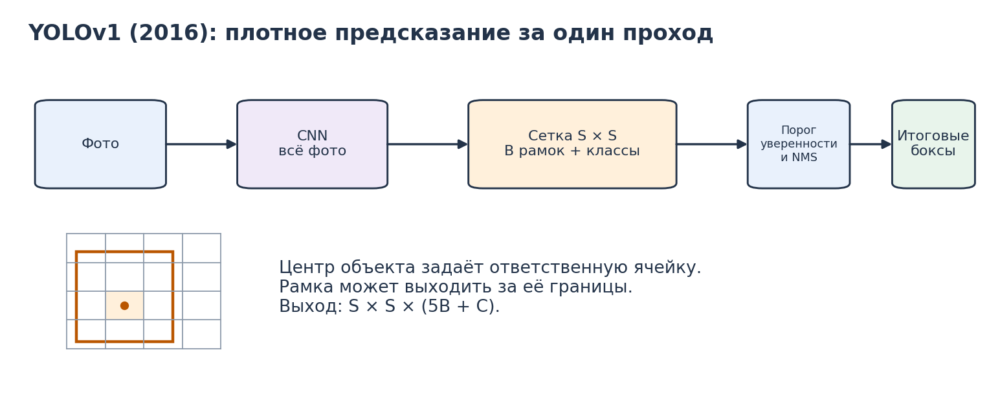


В оригинале выход имеет размер $S\times S\times(5B+C)$: B рамок с четырьмя
координатами и уверенностью плюс C оценок класса на ячейку.
S - число ячеек вдоль стороны сетки. На PASCAL VOC, наборе с 20 классами,
использовали S=7, B=2, C=20. У оригинального YOLO после сети есть NMS.
Другие версии YOLO отличаются головами, масштабами признаков, архитектурой и постобработкой.
[Статья YOLOv1](https://arxiv.org/abs/1506.02640).


### DETR: предсказать фиксированное множество объектов

**DETR (Detection Transformer, 2020)** получает признаки CNN и добавляет
информацию о положении на изображении. **Энкодер трансформера** уточняет
признаки каждого участка изображения, учитывая другие участки. За это отвечает
**механизм внимания (attention)**: он определяет, какие признаки сильнее повлияют
друг на друга.

У **декодера** есть фиксированное число **обучаемых векторов-запросов (object queries)**.
Каждый служит слотом для одного ответа: класса и рамки. Декодер обновляет эти
векторы с учётом признаков изображения. Если объект для слота не нашёлся,
он должен предсказать «нет объекта». В исходном DETR обычно N=100 слотов.


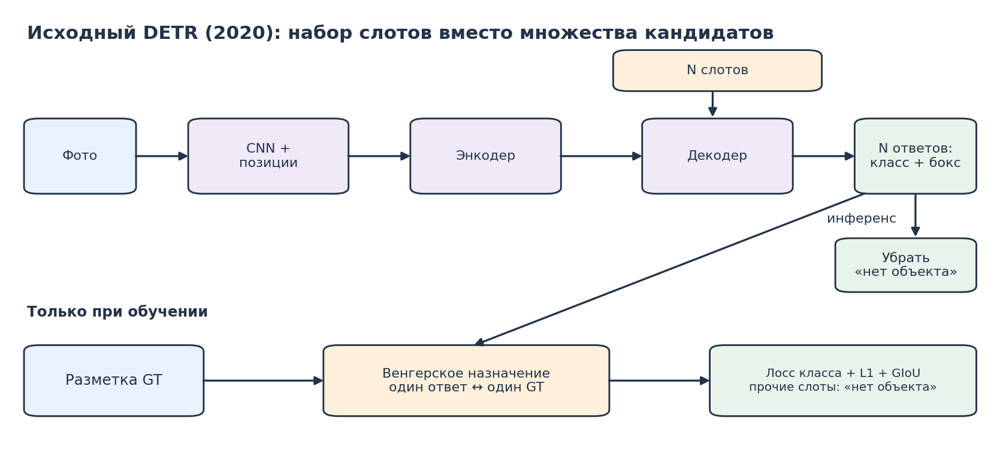


При обучении сначала для каждой возможной пары «слот - GT» считаем стоимость:
насколько ошибочны класс и рамка. Затем
[венгерский алгоритм](https://web.eecs.umich.edu/~pettie/matching/Kuhn-hungarian-assignment.pdf)
выбирает пары так, чтобы **общая стоимость была минимальной**. Каждый GT получает
один слот. Одному слоту нельзя назначить несколько GT. Для назначенных пар считаются лоссы
класса и координат (L1 + GIoU), остальные слоты учатся отвечать «нет объекта».
L1 - сумма модулей ошибок координат; **GIoU (Generalized IoU)** сравнивает геометрию рамок,
в том числе когда они не пересекаются.
В AP мы разбирали ответы по очереди, начиная с высокого score. Здесь алгоритм
выбирает все пары совместно.

При инференсе венгерский алгоритм не нужен. В исходном DETR нет обязательного
NMS: выдавать уникальные объекты учит сама функция потерь. Ответы «нет объекта»
отбрасываются.
[Статья DETR](https://arxiv.org/abs/2005.12872).

| Подход | Откуда берутся кандидаты | Как работает с дублями в показанной версии |
|---|---|---|
| Faster R-CNN | RPN предлагает области, RoI-голова их уточняет | NMS |
| YOLOv1 | Плотные предсказания по сетке | NMS |
| Исходный DETR | N обучаемых слотов | Взаимно однозначное назначение при обучении |